# Data Exploration

This notebook explores the UCI Heart Disease dataset to examine its
structure, data types, missing values, and feature correlations.

In [ ]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

### Data Loading

Load the dataset and assign column names to the features and target.
Missing values represented by `?` are converted to `NaN`.

In [ ]:
columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs",
    "restecg", "thalach", "exang", "oldpeak", "slope",
    "ca", "thal", "num"
]

df = pd.read_csv("../data/processed.cleveland.data", header=None, names=columns, na_values="?")

### Dataset Overview

Examine descriptive statistics to understand the distributions and
ranges of the numerical features.

In [ ]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


Check the data types of each column to identify how the features
are represented in the dataset.

In [ ]:
df.dtypes

age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
num           int64
dtype: object

Inspect the unique values of the target variable `num` to understand
how heart disease severity is encoded in the original dataset.

In [ ]:
df["num"].unique()

array([0, 2, 1, 3, 4])

### Missing Values

Count the missing values in each column to assess the extent of
incomplete data.

In [ ]:
df.isna().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Examine the descriptive statistics after removing rows containing
missing values, as these rows will be excluded during preprocessing.

In [ ]:
df.dropna().describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000
mean,54.542088,0.676768,3.158249,131.693603,247.350168,0.144781,0.996633,149.599327,0.326599,1.055556,1.602694,0.676768,4.730640,0.946128
std,9.049736,0.468500,0.964859,17.762806,51.997583,0.352474,0.994914,22.941562,0.469761,1.166123,0.618187,0.938965,1.938629,1.234551
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,243.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,276.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


### Correlation Analysis

Visualize pairwise Pearson correlations between numerical columns
to identify potential linear relationships between features and the
original target variable.

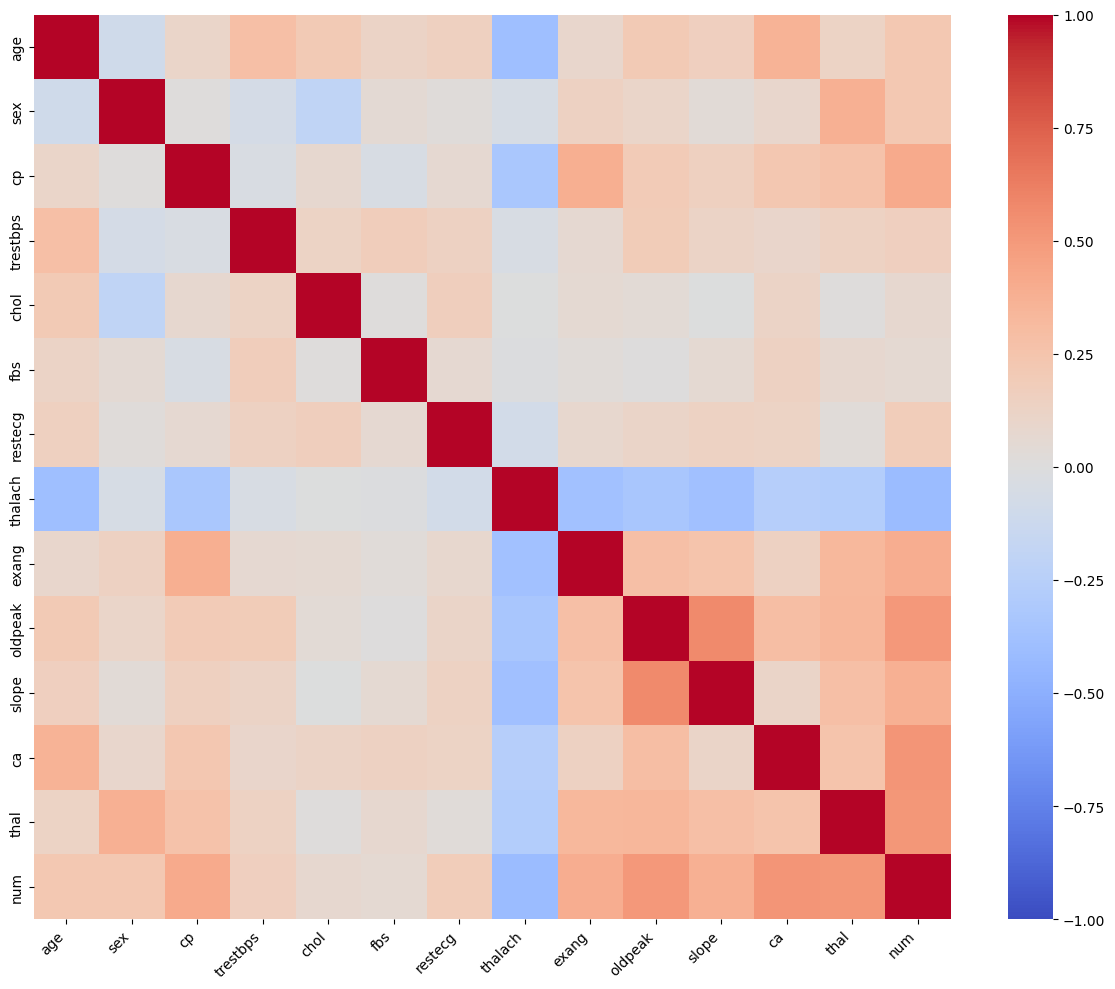

In [ ]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    df.corr(numeric_only=True),
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Identify features whose absolute correlation with `num` exceeds 0.5.
This threshold is used for exploratory purposes and does not imply
causation or determine which features should be used for modeling.

In [ ]:
corr_with_num = df.corr(numeric_only=True)["num"]

best_features = corr_with_num[
    (corr_with_num.abs() > 0.5) &
    (corr_with_num.index != "num")
].index.tolist()

print(best_features)

['oldpeak', 'ca', 'thal']
